# Entrenamiento de una CNN

Se entrena una red convolucional con los mismos datos y el mismo preprocesado que la SVM para comparar ambos enfoques.

- En la SVM las características (HOG, LBP) se diseñan a mano.
- La CNN recibe los píxeles y aprende sus propios filtros.

La red se entrena por épocas. Se separa un 10 % de train como validación para decidir cuándo parar (*early stopping*); el test sigue reservado para la evaluación final.

In [ ]:
import os, sys
from pathlib import Path

# Los notebooks están en notebooks/, se trabaja desde la carpeta del proyecto
if not Path("emociones_utils.py").exists():
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import time, json
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay, recall_score

from emociones_utils import CLASES, NOMBRE_ES

CACHE_IMAGENES = "data/fer6_preprocesado.npz"
RUTA_SVM = "modelos/modelo_emociones.joblib"
RUTA_CNN = "modelos/modelo_emociones_cnn.keras"
CARPETA_RESULTADOS = "resultados"

EPOCAS_MAX = 60
TAM_LOTE = 64
SEMILLA = 0

NOMBRES = [NOMBRE_ES[c] for c in CLASES]
keras.utils.set_random_seed(SEMILLA)
Path(CARPETA_RESULTADOS).mkdir(exist_ok=True)
print("Keras", keras.__version__, "| backend:", keras.backend.backend())

Trabajando en: c:\Users\becha\OneDrive - Universidad de Las Palmas de Gran Canaria\uni\4año_1semestre\VC\Practica\VC-practica\P5\pokemon_emociones
Keras 3.15.1 | backend: tensorflow


## Datos
Se usan las caras ya preprocesadas. La red espera imágenes con un eje de canal, así que pasan de `(N, 48, 48)` a `(N, 48, 48, 1)`. Los pesos por clase equivalen al `class_weight="balanced"` de la SVM.

In [4]:
d = np.load(CACHE_IMAGENES)
X_train_full = d["X_train"][..., None].astype("float32")
y_train_full = d["y_train"]
X_test = d["X_test"][..., None].astype("float32")
y_test = d["y_test"]

X_tr, X_val, y_tr, y_val = train_test_split(X_train_full, y_train_full, test_size=0.10,
                                            stratify=y_train_full, random_state=SEMILLA)
print("train:", X_tr.shape, " val:", X_val.shape, " test:", X_test.shape)

pesos = compute_class_weight("balanced", classes=np.arange(len(CLASES)), y=y_tr)
PESOS_CLASE = {i: float(p) for i, p in enumerate(pesos)}
print("Pesos por clase:", {NOMBRES[i]: round(p, 2) for i, p in PESOS_CLASE.items()})

train: (25445, 48, 48, 1)  val: (2828, 48, 48, 1)  test: (7067, 48, 48, 1)
Pesos por clase: {'enfado': 1.18, 'miedo': 1.15, 'feliz': 0.65, 'neutral': 0.95, 'triste': 0.98, 'sorpresa': 1.49}


## Aumento de datos
Durante el entrenamiento cada imagen se modifica aleatoriamente (espejo, giro, desplazamiento y zoom) para que la red no memorice las imágenes. Estas capas solo actúan al entrenar.

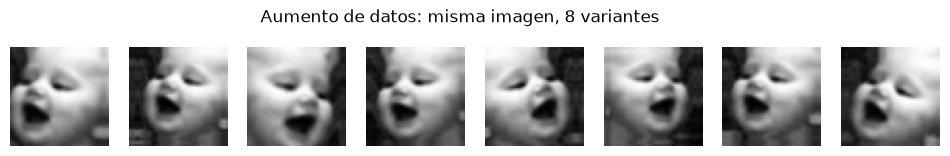

In [5]:
aumento = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomTranslation(0.08, 0.08),
    layers.RandomZoom(0.10),
], name="aumento")

ejemplo = X_tr[:1]
fig, ejes = plt.subplots(1, 8, figsize=(12, 1.8))
for i in range(8):
    ejes[i].imshow(np.array(aumento(ejemplo, training=True))[0, :, :, 0], cmap="gray", vmin=0, vmax=255)
    ejes[i].axis("off")
plt.suptitle("Aumento de datos sobre una misma imagen"); plt.show()

## Arquitectura
Tres bloques convolucionales (32, 64 y 128 filtros). Cada bloque tiene dos convoluciones 3×3 con *batch normalization*, un *max pooling* que reduce el tamaño a la mitad y *dropout*. Después, una capa densa de 256 neuronas y la salida *softmax* con las 6 emociones.

```
48×48×1 → 24×24×32 → 12×12×64 → 6×6×128 → Dense 256 → Dense 6
```

El reescalado a [0, 1] va dentro del modelo, así que en la webcam se le pasa la cara 48×48 directamente.

In [6]:
def bloque(x, filtros):
    for _ in range(2):
        x = layers.Conv2D(filtros, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)
    return layers.Dropout(0.25)(x)

entrada = keras.Input(shape=(48, 48, 1))
x = layers.Rescaling(1.0 / 255)(entrada)
x = aumento(x)
for filtros in (32, 64, 128):
    x = bloque(x, filtros)
x = layers.Flatten()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.5)(x)
salida = layers.Dense(len(CLASES), activation="softmax")(x)

modelo = keras.Model(entrada, salida, name="cnn_emociones")
modelo.compile(optimizer=keras.optimizers.Adam(1e-3),
               loss="sparse_categorical_crossentropy",
               metrics=["accuracy"])
modelo.summary()

Model: "cnn_emociones"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumento (Sequential)            │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 12, 12, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             

 Total params: 1,470,694 (5.61 MB)

 Trainable params: 1,469,286 (5.60 MB)

 Non-trainable params: 1,408 (5.50 KB)

## Entrenamiento
- **EarlyStopping:** para si la pérdida de validación no mejora en 8 épocas y recupera los pesos de la mejor.
- **ReduceLROnPlateau:** reduce el *learning rate* a la mitad si se estanca 3 épocas.

In [7]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=1),
]

t0 = time.time()
historia = modelo.fit(X_tr, y_tr, validation_data=(X_val, y_val),
                      epochs=EPOCAS_MAX, batch_size=TAM_LOTE,
                      class_weight=PESOS_CLASE, callbacks=callbacks, verbose=2)
t_entreno = time.time() - t0
print(f"\nEntrenamiento: {t_entreno / 60:.1f} min en {len(historia.history['loss'])} épocas")

Epoch 1/60
398/398 - 139s - 350ms/step - accuracy: 0.2525 - loss: 1.9877 - val_accuracy: 0.1987 - val_loss: 1.9413 - learning_rate: 0.0010
Epoch 2/60
398/398 - 92s - 230ms/step - accuracy: 0.3671 - loss: 1.5853 - val_accuracy: 0.3851 - val_loss: 1.5299 - learning_rate: 0.0010
Epoch 3/60
398/398 - 113s - 285ms/step - accuracy: 0.4279 - loss: 1.4582 - val_accuracy: 0.4894 - val_loss: 1.3086 - learning_rate: 0.0010
Epoch 4/60
398/398 - 98s - 247ms/step - accuracy: 0.4569 - loss: 1.4014 - val_accuracy: 0.4388 - val_loss: 1.4270 - learning_rate: 0.0010
Epoch 5/60
398/398 - 69s - 174ms/step - accuracy: 0.4819 - loss: 1.3453 - val_accuracy: 0.5255 - val_loss: 1.2028 - learning_rate: 0.0010
Epoch 6/60
398/398 - 73s - 183ms/step - accuracy: 0.4996 - loss: 1.3071 - val_accuracy: 0.5046 - val_loss: 1.2766 - learning_rate: 0.0010
Epoch 7/60
398/398 - 71s - 178ms/step - accuracy: 0.5188 - loss: 1.2604 - val_accuracy: 0.5315 - val_loss: 1.1949 - learning_rate: 0.0010
Epoch 8/60
398/398 - 68s - 171ms

## Curvas de aprendizaje

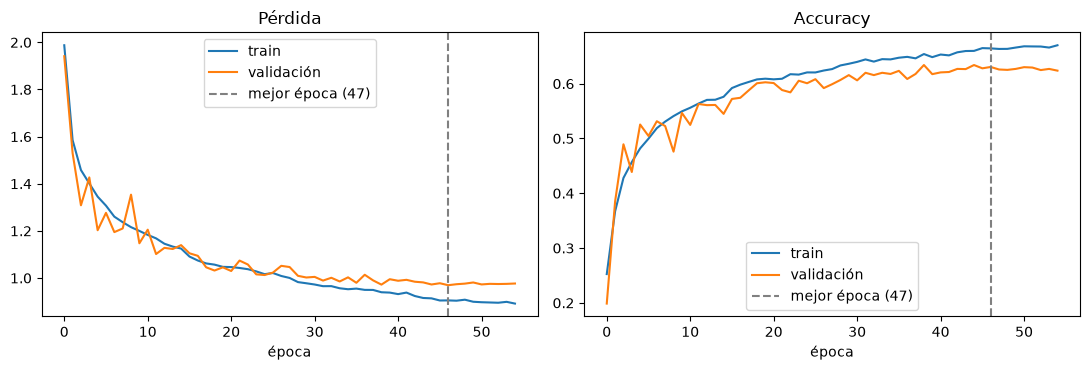

In [8]:
h = historia.history
mejor = int(np.argmin(h["val_loss"]))
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, met, titulo in [(ejes[0], "loss", "Pérdida"), (ejes[1], "accuracy", "Accuracy")]:
    ax.plot(h[met], label="train")
    ax.plot(h["val_" + met], label="validación")
    ax.axvline(mejor, ls="--", c="gray", label=f"mejor época ({mejor + 1})")
    ax.set_title(titulo); ax.set_xlabel("época"); ax.legend()
plt.tight_layout()
plt.savefig(f"{CARPETA_RESULTADOS}/cnn_curvas.png", dpi=150); plt.show()

## Evaluación en test

TEST -> accuracy = 0.640   F1 macro = 0.621

              precision    recall  f1-score   support

      enfado      0.540     0.640     0.585       958
       miedo      0.498     0.437     0.465      1024
       feliz      0.890     0.823     0.855      1774
     neutral      0.548     0.663     0.600      1233
      triste      0.545     0.431     0.481      1247
    sorpresa      0.704     0.776     0.738       831

    accuracy                          0.640      7067
   macro avg      0.621     0.628     0.621      7067
weighted avg      0.643     0.640     0.638      7067



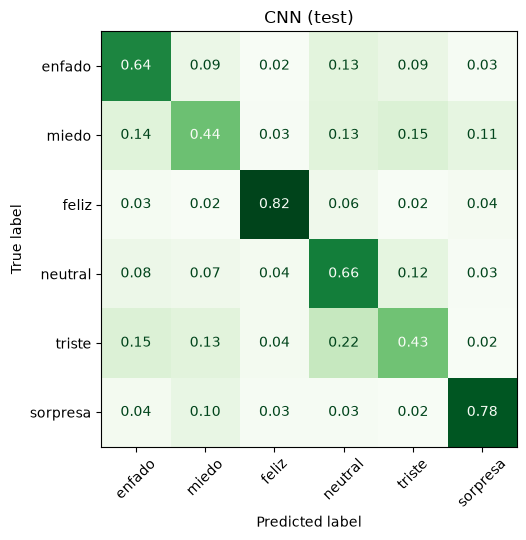

In [9]:
prob = modelo.predict(X_test, batch_size=256, verbose=0)
y_pred = prob.argmax(axis=1)
acc = accuracy_score(y_test, y_pred)
f1m = f1_score(y_test, y_pred, average="macro")
print(f"TEST -> accuracy = {acc:.3f}   F1 macro = {f1m:.3f}\n")
print(classification_report(y_test, y_pred, target_names=NOMBRES, digits=3))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=NOMBRES, normalize="true",
                                        values_format=".2f", cmap="Greens", ax=ax, colorbar=False)
ax.set_title("CNN (test)"); plt.xticks(rotation=45); plt.tight_layout()
plt.savefig(f"{CARPETA_RESULTADOS}/cnn_matriz_confusion.png", dpi=150); plt.show()

## Tiempo de predicción
Tiempo por imagen llamando al modelo con una sola cara, como en la webcam.

In [10]:
modelo(X_test[:1], training=False)   # la primera llamada es más lenta
t0 = time.time()
for i in range(200):
    modelo(X_test[i:i + 1], training=False)
ms_cnn = 1000 * (time.time() - t0) / 200
print(f"CNN: {ms_cnn:.2f} ms por imagen")

CNN: 49.78 ms por imagen


## Comparación con la SVM

                         SVM RBF       CNN
F1 macro (test)            0.554     0.621
Accuracy (test)            0.569     0.640
ms por imagen               48.2      49.8
Entrenamiento (min)          ~28      93.9

Recall por emoción:
  enfado                    0.45      0.64   (+0.19)
  miedo                     0.40      0.44   (+0.04)
  feliz                     0.79      0.82   (+0.03)
  neutral                   0.52      0.66   (+0.15)
  triste                    0.45      0.43   (-0.02)
  sorpresa                  0.69      0.78   (+0.09)


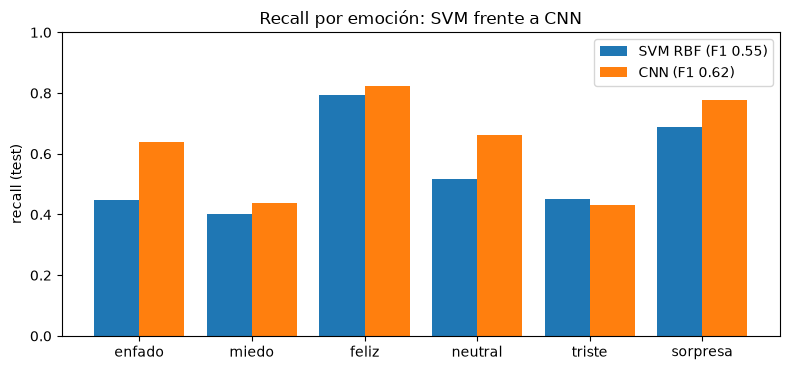

In [11]:
import joblib
from emociones_utils import extraer

svm = joblib.load(RUTA_SVM)
d_img = np.load(CACHE_IMAGENES)
X_svm = np.stack([extraer(im, svm["caract"]) for im in d_img["X_test"]])
y_pred_svm = svm["modelo"].predict(X_svm)

rec_svm = recall_score(y_test, y_pred_svm, average=None)
rec_cnn = recall_score(y_test, y_pred, average=None)

print(f"{'':22s}{'SVM RBF':>10s}{'CNN':>10s}")
print(f"{'F1 macro (test)':22s}{svm['test_f1_macro']:10.3f}{f1m:10.3f}")
print(f"{'Accuracy (test)':22s}{svm['test_accuracy']:10.3f}{acc:10.3f}")
print(f"{'ms por imagen':22s}{svm['ms_por_imagen']:10.1f}{ms_cnn:10.1f}")
print(f"{'Entrenamiento (min)':22s}{'~28':>10s}{t_entreno / 60:10.1f}")
print("\nRecall por emoción:")
for i, n in enumerate(NOMBRES):
    print(f"  {n:20s}{rec_svm[i]:10.2f}{rec_cnn[i]:10.2f}   ({rec_cnn[i] - rec_svm[i]:+.2f})")

x = np.arange(len(NOMBRES))
plt.figure(figsize=(8, 3.8))
plt.bar(x - 0.2, rec_svm, 0.4, label=f"SVM RBF (F1 {svm['test_f1_macro']:.2f})")
plt.bar(x + 0.2, rec_cnn, 0.4, label=f"CNN (F1 {f1m:.2f})")
plt.xticks(x, NOMBRES); plt.ylabel("recall (test)"); plt.ylim(0, 1); plt.legend()
plt.title("Recall por emoción: SVM frente a CNN"); plt.tight_layout()
plt.savefig(f"{CARPETA_RESULTADOS}/comparacion_svm_cnn.png", dpi=150); plt.show()

## Guardar

In [12]:
modelo.save(RUTA_CNN)
print(f"Modelo guardado en {RUTA_CNN} ({Path(RUTA_CNN).stat().st_size / 1e6:.1f} MB)")

json.dump({"modelo": "CNN (3 bloques conv)", "test_accuracy": acc, "test_f1_macro": f1m,
           "ms_por_imagen": ms_cnn, "minutos_entreno": t_entreno / 60,
           "epocas": len(h["loss"]), "mejor_epoca": mejor + 1, "keras": keras.__version__,
           "informe_test": classification_report(y_test, y_pred, target_names=NOMBRES, output_dict=True)},
          open(f"{CARPETA_RESULTADOS}/metricas_cnn.json", "w", encoding="utf-8"),
          indent=2, ensure_ascii=False, default=float)

m2 = keras.models.load_model(RUTA_CNN)
p = np.array(m2(X_test[:1], training=False))[0]
print("Comprobación -> predicción:", NOMBRES[p.argmax()], f"({p.max():.0%}) | real:", NOMBRES[y_test[0]])

Modelo guardado en modelos/modelo_emociones_cnn.keras (17.8 MB)
Prueba de carga -> predicción: enfado (98%) | real: enfado


## Resultados

| | SVM RBF (HOG+LBP) | CNN |
|---|---|---|
| F1 macro (test) | 0,554 | **0,621** |
| Accuracy (test) | 0,569 | **0,640** |
| Entrenamiento | ~28 min | 94 min (55 épocas, CPU) |
| Tamaño del modelo | 66 MB | 18 MB |

- La CNN mejora en casi todas las emociones, sobre todo enfado (+0,19 de recall) y neutral (+0,15). Miedo sigue siendo la más difícil con los dos modelos (0,44), lo que apunta a una limitación del propio dataset más que del modelo. Triste se queda igual.
- En las curvas, train y validación van juntas hasta la época 25 aproximadamente; después aparece un sobreajuste leve que el dropout y el aumento de datos mantienen controlado. La mejor época es la 47.
- Llamando al modelo directamente tarda unos 50 ms por imagen, lo mismo que la SVM. Ese tiempo es sobre todo la sobrecarga de ejecutar la red capa a capa con una sola imagen, por eso en el prototipo el modelo se compila con `tf.function`.
- Por estos resultados el prototipo usa la CNN por defecto.